# BLS API exploration

Probe the BLS MCP tools. The MCP server must be running (`python -m mcp_server.server`).

In [1]:
%reload_ext autoreload
%autoreload 2

import sys
sys.path.append('../')

from lib.utils import print_json_vertical
from utils import bls_series_to_arrays, plot_bls_series, bls_point_to_date
from matplotlib import pyplot
from lib import config

from utils import (
    call_tool,
    list_mcp_tools,
    show_all_surveys,
    popular_series,
    fetch_series,
)

pyplot.style.use(config.glyfish_style)

## Available tools

In [2]:
await list_mcp_tools()

fred_category_children: List the child categories for a FRED category.
fred_category_series: List the series contained within a FRED category.
fred_series_info: Fetch metadata for a single FRED series.
fred_series_observations: Return observations for a series (limit defaults to 100).
fred_series_updates: Return recently updated FRED series.
list_releases: List FRED releases — the publications data arrives in, such as the Employment Situation or the H.15 selected interest rates. Returns the release ids that fred_release_series takes.
fred_release_series: List the series that belong to a FRED release.
tiingo_series_info: Fetch metadata for a Tiingo ticker (ETF, mutual fund, or stock), including its available date range.
tiingo_price_series: Return the end-of-day price series (OHLCV plus split/dividend-adjusted prices) for a Tiingo ticker. Provide start_date/end_date as YYYY-MM-DD for a range; omit for the latest day.
bls_series_data: Fetch observations for one or more BLS series IDs (up

## All surveys

In [3]:
surveys = await show_all_surveys()

AP: Consumer Price Index - Average Price Data
BD: Business Employment Dynamics
BG: Collective Bargaining Agreements-State and Local Government
BP: Collective Bargaining Agreements-Private Sector
CA: Biennial Nonfatal Case and Demographic numbers and rates: selected characteristics
CB: Biennial Nonfatal Case and Demographic numbers and rates: selected characteristics
CC: Employer Costs for Employee Compensation
CD: Nonfatal cases involving days away from work: selected characteristics
CE: Employment, Hours, and Earnings from the Current Employment Statistics survey (National)
CF: Census of Fatal Occupational Injuries
CH: Nonfatal cases involving days away from work: selected characteristics (2003 - 2010)
CI: Employment Cost Index
CM: Employer Costs for Employee Compensation
CS: Nonfatal cases involving days away from work: selected characteristics (2011 forward)
CU: Consumer Price Index - All Urban Consumers
CW: Consumer Price Index - Urban Wage Earners and Clerical Workers
CX: Consumer

## Single survey metadata

In [4]:
result = await call_tool("bls_survey_info", {"survey_abbreviation": "TU"})

if result is not None and result.structured_content is not None:
    print_json_vertical(result.structured_content)


{
  "notices": [],
  "survey": {
    "allows_net_change": false,
    "allows_percent_change": false,
    "has_annual_averages": false,
    "survey_abbreviation": "TU",
    "survey_name": "American Time Use"
  }
}


## Popular series (overall, then for one survey)

In [5]:
print(await popular_series())

['CUUR0000SA0', 'LNS14000000', 'CES0000000001', 'CUSR0000SA0', 'CUUR0000SA0L1E', 'CUSR0000SA0L1E', 'CES0500000003', 'WPUFD49104', 'WPUFD4', 'WPSFD4', 'ISU00000000031004', 'ISU00000000031006', 'ISU00000000031029', 'ISU00000000031001', 'ISU00000000031018', 'ISU00000000031051', 'ISU00000000031048', 'ISU00000000031005', 'ISU00000000031017', 'ISU00000000031021', 'ISU00000000031019', 'ISU00000000031022', 'ISU00000000031039', 'ISU00000000031026', 'ISU00000000031027']


In [6]:
print(await popular_series("LA"))

['LASST260000000000003', 'LASST010000000000003', 'LASST360000000000003', 'LASST040000000000003', 'LASST020000000000003', 'LASST480000000000003', 'LASST060000000000003', 'LASST170000000000003', 'LASST120000000000003', 'LAUCN260650000000003', 'LASST130000000000003', 'LAUCN261630000000003', 'LAUCN260490000000003', 'LAUCN260770000000003', 'LAUCN260810000000003', 'LAUCN261390000000003', 'LAUCN261610000000003', 'LAUCN261250000000003', 'LAUCN260990000000003', 'LAUCN261450000000003', 'LAUCN260170000000003', 'LAUCN261210000000003', 'LAUCN260930000000003', 'LASST370000000000003', 'LASST390000000000003']


## Latest datapoint for a series

In [7]:
result = await call_tool("bls_series_latest", {"series_id": "LNS14000000"})

if result is not None and result.structured_content is not None:
    print_json_vertical(result.structured_content)


{
  "notices": [],
  "series": [
    {
      "catalog": null,
      "observations": [
        {
          "aspects": [],
          "calculations": null,
          "date": "2026-09-01",
          "footnotes": [],
          "latest": true,
          "period": "M09",
          "period_name": "September",
          "period_type": "monthly",
          "value": "4.2",
          "year": "2026"
        }
      ],
      "series_id": "LNS14000000"
    }
  ]
}


## Series data with catalog + calculations

In [8]:
result = await call_tool(
    "bls_series_data",
    {
        "series_ids": ["LNS14000000"],
        "start_year": 2003,
        "end_year": 2023,
        "catalog": True,
        "calculations": True,
    },
)

if result is not None and result.structured_content is not None:
    print_json_vertical(result.structured_content)
else:
    print("No result or structured_content is None")


{
  "notices": [
    "Year range has been reduced to the system-allowed limit of 20 years."
  ],
  "series": [
    {
      "catalog": {
        "additional_fields": {
          "commerce_industry": "All Industries",
          "cps_labor_force_status": "Unemployment rate",
          "demographic_age": "16 years and over",
          "demographic_education": "All educational levels",
          "demographic_ethnic_origin": "All Origins",
          "demographic_gender": "Both Sexes",
          "demographic_race": "All Races",
          "occupation": "All Occupations"
        },
        "measure_data_type": "Percent or rate",
        "seasonality": "Seasonally Adjusted",
        "series_id": "LNS14000000",
        "series_title": "(Seas) Unemployment Rate",
        "survey_abbreviation": "LN",
        "survey_name": "Labor Force Statistics from the Current Population Survey"
      },
      "observations": [
        {
          "aspects": [],
          "calculations": {
            "net_chang

## Plot Series Data

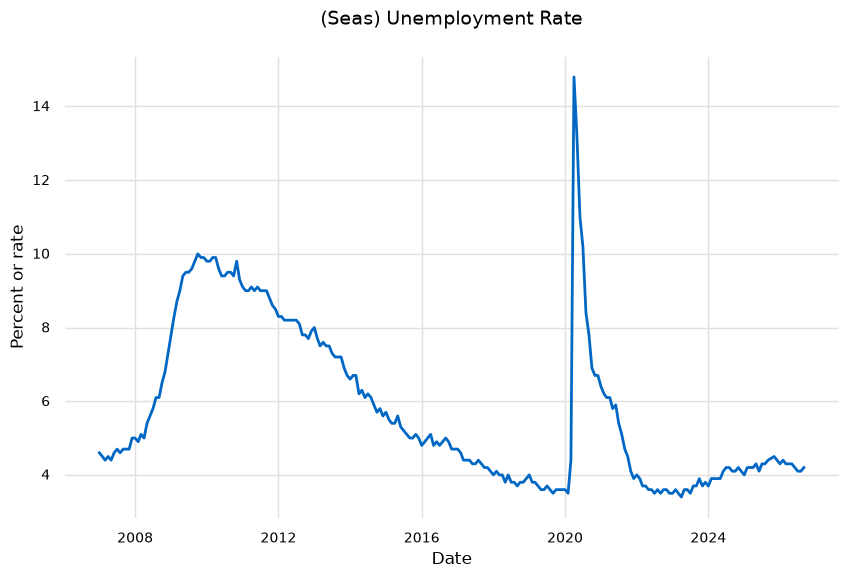

In [9]:
result = await call_tool("bls_series_data", {
    "series_ids": ["LNS14000000"], "start_year": 2007, "end_year": 2026, "catalog": True,
})

if result is not None and result.structured_content is not None:
    series = result.structured_content["series"][0]
    plot_bls_series(series)
else:
    print("No result or structured_content is None")
